# Transition tensors from the Reddit climate threads

Notation (as in Kozitsin): s own class of the replier, l influencer in the dyadic case (class of the parent), g influencer in the group case (6 categories from the group’s mean and variance), k output class.
This notebook only calls the three modules in the parent folder (config.py, events.py, tensors.py). Every threshold lives in config.py; change it there, restart the kernel, and run again.
Part A (this version): set up, load, and choose the cut-points from histograms, before looking at any transition.

In [1]:
import sys
from pathlib import Path

here = Path.cwd().resolve()
candidates = [here, *here.parents, here / "opinion_transitions"]
ROOT = next((p for p in candidates if (p / "config.py").exists() and (p / "events.py").exists()), None)
if ROOT is None:
    raise FileNotFoundError(f"config.py and events.py not found from {here}; "
                            f"set ROOT = Path('/path/to/opinion_transitions') by hand")
sys.path.insert(0, str(ROOT))

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

%load_ext autoreload
%autoreload 2

import config as cfg      # two UserWarnings about placeholder cuts are expected until Part A is finished
import events
import tensors

pd.set_option("display.width", 160)
pd.set_option("display.max_columns", 40)
print("project root:", ROOT)
print("config loaded from:", cfg.__file__)
print("raw data    :", cfg.DATA_RAW, "| exists:", cfg.DATA_RAW.exists())
print("cache       :", cfg.DATA_CACHE, "| exists:", cfg.DATA_CACHE.exists())

project root: /home/guial/projects/empirical-opinion-dynamics/reddit_climate
config loaded from: /home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py
raw data    : /home/guial/projects/empirical-opinion-dynamics/reddit_climate/data/raw/filtered_subs_and_threads_anonymized | exists: True
cache       : /home/guial/projects/empirical-opinion-dynamics/reddit_climate/data/cache | exists: True


/home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py:193: UserWarning: CUTS are placeholders: choose them from the score histogram before looking at transitions, then set CUTS_CHOSEN_FROM_HISTOGRAM = True.
  validate()
/home/guial/projects/empirical-opinion-dynamics/reddit_climate/config.py:193: UserWarning: VAR_CUT is a placeholder: choose it from the histogram of group variances before looking at transitions, then set VAR_CUT_CHOSEN_FROM_HISTOGRAM = True.
  validate()


# 1. Load Raw Tables

In [2]:
threads, submissions = events.load_raw()
print("comments   :", f"{len(threads):,}", "| paper Table 1: 363,350 (we expect about 78%)")
print("submissions:", f"{len(submissions):,}")
threads.head(3)

comments   : 282,497 | paper Table 1: 363,350 (we expect about 78%)
submissions: 6,251


,comm_id,sub_id,parent_id,subreddit_id,author_id,created_at,predicted_stance_scores,subreddit,thread_id
0,comm71631,t3_sub3423,t1_comm71632,r/4,author26899,2021-02-22 04:26:38,NaN,subreddit4,lowvyz
1,comm71633,t3_sub3423,t1_comm71634,r/4,author26899,2021-02-22 04:25:20,0.0,subreddit4,lowvyz
2,comm71635,t3_sub3423,t1_comm71636,r/4,author19952,2021-02-21 20:33:18,NaN,subreddit4,lowvyz


In [3]:
paper = {"bayarea": (181, 7743), "California": (148, 7353), "collapse": (2429, 194695),
         "news": (385, 60509), "politics": (490, 43721), "AskReddit": (2618, 49329)}   # (submissions, comments)

by_sr = pd.DataFrame({"submissions": submissions.groupby(cfg.RAW_SUBREDDIT_ID).size(),
                      "comments": threads.groupby(cfg.RAW_SUBREDDIT_ID).size()})
by_sr["name_in_config"] = by_sr.index.map(cfg.SUBREDDIT_NAMES)
by_sr["paper_submissions"] = by_sr["name_in_config"].map(lambda n: paper.get(n, (None, None))[0])
by_sr["paper_comments"] = by_sr["name_in_config"].map(lambda n: paper.get(n, (None, None))[1])
by_sr["share_of_paper_comments"] = (by_sr["comments"] / by_sr["paper_comments"]).round(2)
by_sr["names_match"] = by_sr["submissions"] == by_sr["paper_submissions"]
by_sr

,submissions,comments,name_in_config,paper_submissions,paper_comments,share_of_paper_comments,names_match
subreddit_id,,,,,,,
r/0,181,6298,bayarea,181,7743,0.81,True
r/1,148,4910,California,148,7353,0.67,True
r/2,2429,175033,collapse,2429,194695,0.90,True
r/3,385,37568,news,385,60509,0.62,True
r/4,490,26845,politics,490,43721,0.61,True
r/5,2618,31843,AskReddit,2618,49329,0.65,True


# 2. Choose CUTS from the histogram of raw scores

items: 288,748 | scored: 172,278 (59.7%) | NI: 116,470


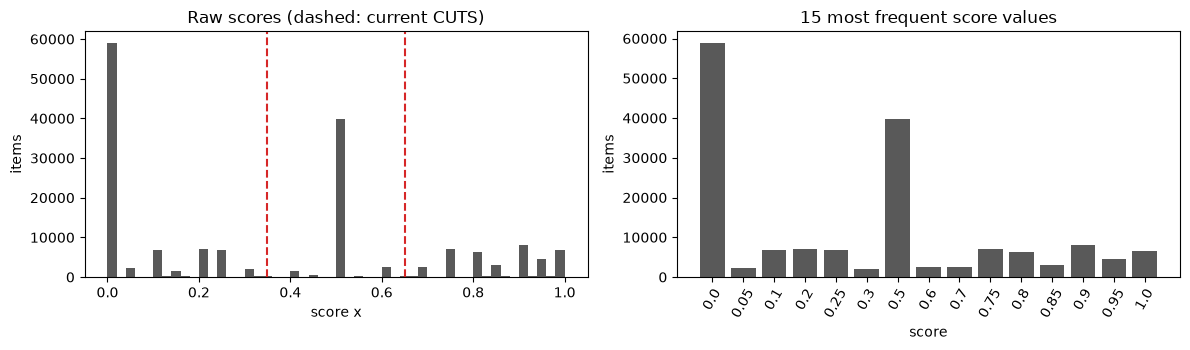

In [4]:
items = events.build_items(threads, submissions)
x = items["x"].dropna()
print(f"items: {len(items):,} | scored: {len(x):,} ({len(x) / len(items):.1%}) | NI: {items['x'].isna().sum():,}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.6))
ax[0].hist(x, bins=50, color="0.35")
for c in cfg.CUTS:
    ax[0].axvline(c, color="C3", ls="--")
ax[0].set(title="Raw scores (dashed: current CUTS)", xlabel="score x", ylabel="items")
top = x.round(2).value_counts().head(15).sort_index()
ax[1].bar(top.index.astype(str), top.values, color="0.35")
ax[1].set(title="15 most frequent score values", xlabel="score", ylabel="items")
ax[1].tick_params(axis="x", rotation=60)
plt.tight_layout(); plt.show()

In [5]:
cls = pd.Series(events.to_class(x, cfg.CUTS)).map(dict(enumerate(cfg.CLASS_LABELS)))
print("share of scored items per class with the current CUTS", cfg.CUTS)
print(cls.value_counts(normalize=True).reindex(cfg.CLASS_LABELS).round(3).to_string())
for c in cfg.CUTS:
    print(f"items within 0.02 of cut {c}: {((x - c).abs() <= 0.02).mean():.1%}")

share of scored items per class with the current CUTS (0.35, 0.65)
against    0.502
neutral    0.267
favour     0.231
items within 0.02 of cut 0.35: 0.3%
items within 0.02 of cut 0.65: 0.2%


In [20]:
for cuts in [(0.30, 0.70), (0.35, 0.65), (0.40, 0.60), (0.45, 0.55)]:
    s = pd.Series(events.to_class(x, cuts)).map(dict(enumerate(cfg.CLASS_LABELS)))
    print(cuts, s.value_counts(normalize=True).reindex(cfg.CLASS_LABELS).round(3).to_dict())

(0.3, 0.7) {'against': 0.489, 'neutral': 0.296, 'favour': 0.215}
(0.35, 0.65) {'against': 0.502, 'neutral': 0.267, 'favour': 0.231}
(0.4, 0.6) {'against': 0.505, 'neutral': 0.262, 'favour': 0.233}
(0.45, 0.55) {'against': 0.515, 'neutral': 0.236, 'favour': 0.249}


# 3. Choose VAR_CUT from the histogram of group variances

In [6]:
rep = events.build_replies(items)
rep = events.add_own_opinion(rep, items)
rep = events.add_group_stats(rep)
print(f"replies: {len(rep):,} | with a group of >= {cfg.MIN_MEMBERS} scored members: {(rep['g_n'] >= cfg.MIN_MEMBERS).sum():,}")
print("group size (scored members) for replies that have a group:")
print(rep.loc[rep["g_n"] >= 1, "g_n"].describe(percentiles=[.5, .9, .99]).round(1).to_string())

replies: 282,497 | with a group of >= 2 scored members: 67,563
group size (scored members) for replies that have a group:
count    135080.0
mean          8.0
std          20.5
min           1.0
50%           2.0
90%          19.0
99%         100.0
max         336.0


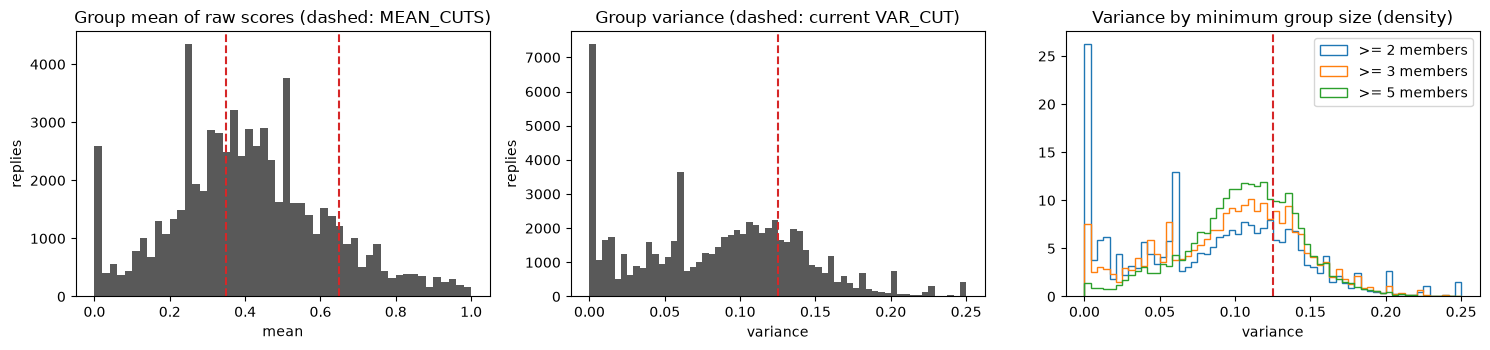

In [7]:
grp = rep[rep["g_n"] >= cfg.MIN_MEMBERS]
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
ax[0].hist(grp["g_mu"], bins=50, color="0.35")
for c in cfg.MEAN_CUTS:
    ax[0].axvline(c, color="C3", ls="--")
ax[0].set(title="Group mean of raw scores (dashed: MEAN_CUTS)", xlabel="mean", ylabel="replies")
ax[1].hist(grp["g_var"], bins=60, color="0.35")
ax[1].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[1].set(title="Group variance (dashed: current VAR_CUT)", xlabel="variance", ylabel="replies")
for n_min, col in ((2, "C0"), (3, "C1"), (5, "C2")):
    ax[2].hist(rep.loc[rep["g_n"] >= n_min, "g_var"], bins=60, histtype="step", density=True, color=col, label=f">= {n_min} members")
ax[2].axvline(cfg.VAR_CUT, color="C3", ls="--")
ax[2].set(title="Variance by minimum group size (density)", xlabel="variance"); ax[2].legend()
plt.tight_layout(); plt.show()

In [8]:
q = grp["g_var"].quantile([.1, .25, .5, .6, .7, .75, .8, .9]).round(4)
print("quantiles of the group variance (groups with >= MIN_MEMBERS members):")
print(q.to_string())
print("\nshare of groups called 'divided' for some candidate VAR_CUT values:")
cand = [0.02, 0.04, 0.06, 0.08, 0.10, 0.125, 0.15]
print(pd.Series({c: (grp["g_var"] >= c).mean() for c in cand}).round(3).to_string())
print("\nNote: with 2 members the variance is (a - b)^2 / 4, so VAR_CUT = 0.125 means the two scores differ by > 0.71.")

quantiles of the group variance (groups with >= MIN_MEMBERS members):
0.10    0.0025
0.25    0.0400
0.50    0.0900
0.60    0.1052
0.70    0.1186
0.75    0.1255
0.80    0.1339
0.90    0.1544

share of groups called 'divided' for some candidate VAR_CUT values:
0.020    0.820
0.040    0.756
0.060    0.663
0.080    0.551
0.100    0.434
0.125    0.255
0.150    0.113

Note: with 2 members the variance is (a - b)^2 / 4, so VAR_CUT = 0.125 means the two scores differ by > 0.71.


In [9]:
def category_fill(min_members):
    d = rep[(rep["g_n"] >= min_members) & rep[cfg.COL_S].notna()]
    mean_level = events.to_class(d["g_mu"], cfg.MEAN_CUTS)
    g = (2 * mean_level + (d["g_var"] >= cfg.VAR_CUT)).astype(int)
    tab = pd.crosstab(d[cfg.COL_S].astype(int), g).reindex(index=range(cfg.N_CLASSES), columns=range(cfg.N_G), fill_value=0)
    tab.index = [f"s={l}" for l in cfg.CLASS_LABELS]
    tab.columns = list(cfg.G_LABELS)
    return tab

for m in (2, 3):
    print(f"group events per (s, g) cell with >= {m} members (before date / gap filters):")
    display(category_fill(m))

group events per (s, g) cell with >= 2 members (before date / gap filters):


,lean-against-consensus,lean-against-divided,centre-consensus,centre-divided,lean-favour-consensus,lean-favour-divided
s=against,7215,962,6332,4396,2363,155
s=neutral,3488,441,3334,2209,1268,71
s=favour,3212,434,3038,2018,1257,77


group events per (s, g) cell with >= 3 members (before date / gap filters):


,lean-against-consensus,lean-against-divided,centre-consensus,centre-divided,lean-favour-consensus,lean-favour-divided
s=against,5013,962,4966,3554,1190,155
s=neutral,2381,441,2576,1776,634,71
s=favour,2152,434,2378,1636,594,77


# B-1 Test composition representation 

In [10]:
cfg.set_classes(3)                      # try 2 as well
res = events.build_events(threads, submissions, verbose=False)
res["funnel_comp"]

,step,n,share_of_previous,share_of_comments
0,comments,282497,NaN,1.000
1,reply is scored (not NI),167274,0.592,0.592
2,author known,167274,1.000,0.592
3,parent present in the data,156532,0.936,0.554
4,reply within 2020-07-01 .. 2022-12-31,156517,1.000,0.554
5,replier has an earlier scored item (own opinio...,110131,0.704,0.390
6,group has >= 2 scored members,42268,0.384,0.150
7,group has at most 5 members -> composition e...,22128,0.524,0.078


In [11]:
events.compare_fill(res).T

summary,l parent class,g mean x variance,g (comp events),c composition
influencer,l,g,g,c
categories,3,6,6,52
rows,9,18,18,156
rows_nonempty,9,18,18,154
events,87032,42268,22128,22128
median_R,8045.0,2113.5,1063.5,64.5
min_R_nonempty,5550,71,58,1
cells_sk_zero,0.0,0.0,0.0,0.025641
rows_below_10,0.0,0.0,0.0,0.076923
events_in_rows_below_10,0.0,0.0,0.0,0.00226


In [12]:
display(events.fill_by_size(res["comp"]).round(3))

,bin,sizes,cells,cells_observed,events,events_per_cell,rows_below_min,share_of_events
0,0,2,6,6,11279,626.611,0.111,0.510
1,1,3,10,10,5149,171.633,0.867,0.233
2,2,4,15,15,3330,74.000,1.000,0.150
3,3,5,21,21,2370,37.619,1.000,0.107


,s,cell,s_label,label,R,n_k0,n_k1,n_k2,low
88,1,36,neutral,n=5: 0-5-0,0,0,0,0,True
140,2,36,favour,n=5: 0-5-0,0,0,0,0,True
36,0,36,against,n=5: 0-5-0,1,1,0,0,True
72,1,20,neutral,n=4: 0-4-0,3,2,1,0,True
139,2,35,favour,n=5: 0-4-1,3,1,2,0,True
87,1,35,neutral,n=5: 0-4-1,3,1,1,1,True
124,2,20,favour,n=4: 0-4-0,4,3,0,1,True
35,0,35,against,n=5: 0-4-1,6,2,0,4,True
135,2,31,favour,n=5: 0-0-5,6,2,1,3,True
145,2,41,favour,n=5: 1-4-0,8,4,2,2,True


,s,cell,s_label,label,R,n_k0,n_k1,n_k2,low
109,2,5,favour,n=2: 2-0-0,591,321,123,147,False
108,2,4,favour,n=2: 1-1-0,601,296,165,140,False
56,1,4,neutral,n=2: 1-1-0,622,299,181,142,False
55,1,3,neutral,n=2: 1-0-1,633,278,175,180,False
57,1,5,neutral,n=2: 2-0-0,639,352,169,118,False
0,0,0,against,n=2: 0-0-2,696,298,157,241,False
1,0,1,against,n=2: 0-1-1,796,358,218,220,False
3,0,3,against,n=2: 1-0-1,1199,627,287,285,False
4,0,4,against,n=2: 1-1-0,1206,632,335,239,False
5,0,5,against,n=2: 2-0-0,1263,748,311,204,False


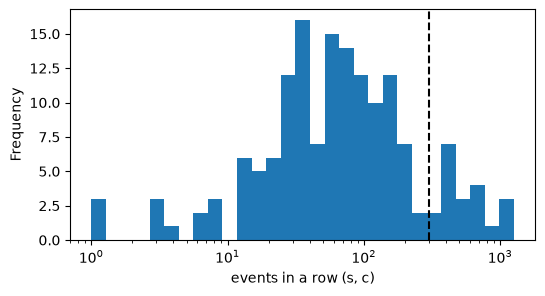

In [13]:
t = events.fill_table(res["comp"], cfg.COL_C)
display(t.sort_values("R").head(10)); display(t.sort_values("R").tail(10))
ax = t["R"].clip(lower=1).plot.hist(bins=np.logspace(0, np.log10(t["R"].max() + 1), 30), logx=True, figsize=(6, 3))
ax.axvline(cfg.MIN_ROW_EVENTS, color="k", ls="--"); ax.set_xlabel("events in a row (s, c)"); plt.show()

In [14]:
scan = events.scan_compositions(threads, submissions, ms=(2, 3), max_sizes=(3, 4, 5, 6), grids=(3, 4, 6))
scan.round(3)

,m,mode,option,categories,rows,events,median_R,min_R_nonempty,rows_below_300,events_in_rows_below_300,prior_weight,cmi_bias_bits
0,2,counts,n<=3,7,14,16428,936.5,283,0.143,0.035,0.040,0.001
1,2,counts,n<=4,12,24,19758,555.0,104,0.250,0.065,0.055,0.001
2,2,counts,n<=5,18,36,22128,323.5,50,0.417,0.121,0.069,0.001
3,2,counts,n<=6,25,50,23971,261.5,17,0.580,0.189,0.083,0.001
4,2,shares,grid 1/3,4,8,42268,5181.0,1917,0.000,0.000,0.009,0.000
5,2,shares,grid 1/4,5,10,42268,3387.5,1788,0.000,0.000,0.012,0.000
6,2,shares,grid 1/6,7,14,42268,3114.5,778,0.000,0.000,0.016,0.000
7,3,counts,n<=3,16,48,16428,214.5,30,0.583,0.249,0.116,0.004
8,3,counts,n<=4,31,93,19758,115.0,3,0.785,0.376,0.157,0.007
9,3,counts,n<=5,52,156,22128,64.5,1,0.872,0.443,0.194,0.010
